In [1]:
import os
import io
import re
import sys
import json
import math
import time
import random
import numpy as np
import pandas as pd
import SimpleITK as sitk

import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm import tqdm
from collections import defaultdict
import matplotlib.pyplot as plt


def read_sitk(path):
    return sitk.GetArrayFromImage(sitk.ReadImage(path))


def write_sitk(
    array: np.ndarray,
    save_path: str,
    spacing=(1.0, 1.0, 1.0),
    origin=(0.0, 0.0, 0.0),
    direction=None,
):
    if array.ndim != 3:
        raise ValueError(f"Expected a 3D array [D, H, W], got shape {array.shape}")

    # NumPy [z, y, x] -> SimpleITK image
    image = sitk.GetImageFromArray(array)

    # SimpleITK metadata uses [x, y, z] order
    image.SetSpacing(tuple(spacing))
    image.SetOrigin(tuple(origin))

    if direction is not None:
        image.SetDirection(tuple(direction))

    sitk.WriteImage(image, save_path)


def resize_3d_numpy(arr: np.ndarray, target_H: int, target_W: int) -> np.ndarray:
    original_dtype = arr.dtype
    min_val, max_val = arr.min(), arr.max()
    tensor = torch.from_numpy(arr).unsqueeze(0)
    
    if not tensor.is_floating_point():
        tensor = tensor.float()
        
    out_tensor = F.interpolate(
        tensor,
        size=(target_H, target_W),
        mode='bicubic',
        align_corners=False,
        antialias=True,
    )
    
    if np.issubdtype(original_dtype, np.integer):
        out_tensor = out_tensor.round()
        
    return out_tensor.clip(min_val, max_val).squeeze(0).numpy().astype(original_dtype)


def print_array_info(x, name='', compute_stat=False):

    def is_array(inp):
        return hasattr(inp, 'min') and hasattr(inp, 'max') and hasattr(inp, 'mean') and hasattr(inp, 'std')

    if is_array(x):
        xmin = x.min().item()
        xmax = x.max().item()
        if compute_stat:
            mean_val = x.mean().item()
            std_val = x.std().item()
            print(f"--> {name}: shape={tuple(x.shape)}, range=({xmin:.4f}, {xmax:.4f}), mean={mean_val:.4f}, std={std_val:.4f}")
        else:
            print(f"--> {name}: shape={tuple(x.shape)}, range=({xmin:.4f}, {xmax:.4f})")
    else:
        s = f"--> {name}: Not an array "
        if isinstance(x, (list, tuple)):
            s += f"(type={type(x)}, len={len(x)}): "
            for ii, xx in enumerate(x):
                if is_array(xx):
                    xxmin = xx.min().item()
                    xxmax = xx.max().item()
                    if compute_stat:
                        mean_val = x.mean().item()
                        std_val = x.std().item()
                        s += f"\n-----> [{ii}]: shape={tuple(xx.shape)}, range=({xxmin:.4f}, {xxmax:.4f}), mean={mean_val:.4f}, std={std_val:.4f}"
                    else:
                        s += f"\n-----> [{ii}]: shape={tuple(xx.shape)}, range=({xxmin:.4f}, {xxmax:.4f})"
                elif isinstance(xx, (int, float)):
                    s += f"\n-----> [{ii}]: Not an array (type={type(xx)}): {xx}"
                else:
                    s += f"\n-----> [{ii}]: Not an array (type={type(xx)})"

        elif isinstance(x, dict):
            s += f"(type={type(x)}, len={len(x)}): "
            for key, xx in x.items():
                if is_array(xx):
                    xxmin = xx.min().item()
                    xxmax = xx.max().item()
                    if compute_stat:
                        mean_val = x.mean().item()
                        std_val = x.std().item()
                        s += f"\n-----> [{ii}]: shape={tuple(xx.shape)}, range=({xxmin:.4f}, {xxmax:.4f}), mean={mean_val:.4f}, std={std_val:.4f}"
                    else:
                        s += f"\n-----> [{key}]: shape={tuple(xx.shape)}, range=({xxmin:.4f}, {xxmax:.4f})"
                elif isinstance(xx, (int, float)):
                    s += f"\n-----> [{ii}]: Not an array (type={type(xx)}): {xx}"
                else:
                    s += f"\n-----> [{key}]: Not an array (type={type(xx)})"

        else:
            s += f"(type={type(x)})"

        print(s)


def show_multiple_images(
    images, 
    nrows=1, 
    ncols=None, 
    titles=None, 
    suptitle=None, 
    tight=True, 
    cmaps='gray', 
    figsize=None, 
    dpi=None, 
    masks=None,
    set_axis_off=True,
    return_pil=False,
):
    num_imgs = len(images)
    ncols = num_imgs // nrows if ncols is None else ncols
    if nrows * ncols < num_imgs:
        ncols += 1
    num_plots = int(nrows * ncols)
    cmaps = [cmaps] * num_imgs if not isinstance(cmaps, (tuple, list)) else cmaps
    masks = [masks] * num_imgs if not isinstance(masks, (tuple, list)) else masks
    titles = [titles] * num_imgs if not isinstance(titles, (tuple, list)) else titles
    assert num_imgs <= num_plots, f'num_imgs = {num_imgs}, nrows = {nrows}, ncols = {ncols}.'
    fig, axes = plt.subplots(nrows, ncols, squeeze=False, figsize=figsize, dpi=dpi)
    axes = axes.flatten()
    for i in range(num_imgs):
        if isinstance(images[i], torch.Tensor):
            img = images[i].cpu().squeeze()
        elif isinstance(images[i], np.ndarray):
            img = images[i].squeeze()
        elif isinstance(images[i], Image.Image):
            img = np.array(images[i]).squeeze()
        else:
            img = images[i]
        
        mask = masks[i]
        if mask is not None:
            img[mask == 0] = img.min()
        axes[i].imshow(img, cmap=cmaps[i])
        if set_axis_off:
            axes[i].axis('off')
        if titles is not None:
            axes[i].set_title(titles[i])
    
    if suptitle is not None:
        fig.suptitle(suptitle)
    
    if num_imgs < num_plots:
        for i in range(num_imgs, num_plots):
            axes[i].axis('off')
            
    if tight:
        fig.tight_layout()
    
    return None

# Model Construction

In [2]:
from models.medvtok import build_model

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
PRETRAINED_PATH = './weights/ckpt.pth'
model = build_model(pretrained_path=PRETRAINED_PATH)
model = model.eval().to(DEVICE)

✅ Loading checkpoint for medvtok-clip from ./weights/ckpt.pth:
<All keys matched successfully>


# 2D Pipeline

## Data Preparation

In [3]:
img_dir = './data/vis_imgs'

img_paths = [os.path.join(img_dir, f) for f in sorted(os.listdir(img_dir)) if f.endswith('.png')][:4]
resolutions = [768, 512, 384, 256]
imgs = []

for i in range(len(img_paths)):
    img_path = img_paths[i]
    img_shape = (resolutions[i], resolutions[i])
    img = Image.open(img_path).resize(img_shape, Image.LANCZOS)
    imgs.append(img)

## Inference

In [ ]:
def image2tensor(image: Image.Image):
    if isinstance(image, str):
        image = Image.open(image)

    image = image.convert('RGB')
    x = torch.from_numpy(np.array(image)).float()
    x = (x / 255.0) * 2.0 - 1.0   # [-1, 1]
    x = x.permute(2, 0, 1)  # [H, W, 3] -> [3, H, W]
    return x

# MedVTok accepts a list of image tensors with different shapes:
# List[(3, H1, W1), (3, H2, W2), ..., (3, Hn, Wn)]
input_tsrs = [image2tensor(im).to(DEVICE) for im in imgs]
print_array_info(input_tsrs, name='Input image tensors')

with torch.no_grad():
    outputs = model(input_tsrs, decode=True)
    feats = outputs['feats']                # (B, 1152)
    patch_tokens = outputs['patch_tokens']  # List[(1, n_patches_0, 1152), ...]
    recons = outputs['recons']              # List[(3, H1, W1), ... (3, Hn, Wn)]

print_array_info(feats, 'Global features')
print_array_info(patch_tokens, 'Patch tokens')

--> Input image tensors: Not an array (type=<class 'list'>, len=4): 
-----> [0]: shape=(3, 768, 768), range=(-0.9373, 1.0000)
-----> [1]: shape=(3, 512, 512), range=(-1.0000, 1.0000)
-----> [2]: shape=(3, 384, 384), range=(-0.7725, 1.0000)
-----> [3]: shape=(3, 256, 256), range=(-1.0000, 1.0000)
--> Global features: shape=(4, 1152), range=(-9.3590, 7.9130)
--> Patch tokens: Not an array (type=<class 'list'>, len=4): 
-----> [0]: shape=(1, 2304, 1152), range=(-15.8207, 12.3404)
-----> [1]: shape=(1, 1024, 1152), range=(-14.7719, 11.7627)
-----> [2]: shape=(1, 576, 1152), range=(-13.5774, 12.1689)
-----> [3]: shape=(1, 256, 1152), range=(-15.1800, 10.0559)


## Autoencoding Reconstruction

--> Reconstructed image tensors: Not an array (type=<class 'list'>, len=4): 
-----> [0]: shape=(3, 768, 768), range=(-0.9342, 0.9637)
-----> [1]: shape=(3, 512, 512), range=(-1.0000, 1.0000)
-----> [2]: shape=(3, 384, 384), range=(-0.7047, 1.0000)
-----> [3]: shape=(3, 256, 256), range=(-1.0000, 1.0000)


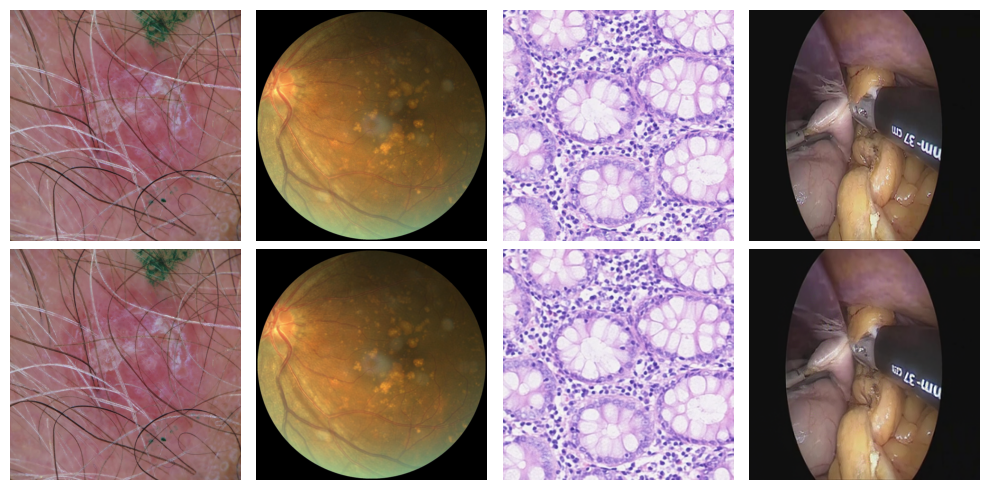

In [6]:
def tensor2image(x: torch.Tensor):
    x = (x + 1.0) / 2. * 255.
    x = x.clip(0, 255).permute(1, 2, 0)

    if hasattr(x, 'cpu'):
        x = x.cpu()
    if hasattr(x, 'numpy'):
        x = x.numpy()

    return np.uint8(x)

print_array_info(recons, 'Reconstructed image tensors')

input_imgs = [tensor2image(x) for x in input_tsrs]
recon_imgs = [tensor2image(x) for x in recons]
show_multiple_images(input_imgs + recon_imgs, nrows=2, figsize=(10, 5))

# 3D Pipeline

## Data preparation

In [7]:
vol_paths = [
    './data/vis_imgs/sample09.nii.gz',
    './data/vis_imgs/sample10.nii.gz',
]
resolutions = [512, 256]
vols = [resize_3d_numpy(read_sitk(p), r, r) for p, r in zip(vol_paths, resolutions)]
print_array_info(vols, 'Input raw volumes')

--> Input raw volumes: Not an array (type=<class 'list'>, len=2): 
-----> [0]: shape=(64, 512, 512), range=(-1000.0000, 1714.0000)
-----> [1]: shape=(37, 256, 256), range=(0.0000, 1125.0000)


## Inference

In [8]:
def volume2tensor(vol, modality='ct', ct_window=(-1000, 1000)):
    if isinstance(vol, str):
        vol = read_sitk(vol)

    vol = torch.from_numpy(vol).float()  # [D, H, W]
    vol = vol.unsqueeze(0).repeat(3, 1, 1, 1)  # [3, D, H, W]

    if modality == 'ct':
        min_val, max_val = min(ct_window), max(ct_window)
    else:  # MR
        min_val, max_val = np.percentile(vol, [0.5, 99.5])
    
    vol = (vol - min_val) / (max_val - min_val) * 2.0 - 1.0

    return vol.clip(-1, 1)


# MedVTok accepts a list of volume tensors with different shapes:
# List[(3, D1, H1, W1), (3, D2, H2, W2), ..., (3, Dn, Hn, Wn)]
input_tsrs = [
    volume2tensor(vols[0], modality='ct').to(DEVICE),
    volume2tensor(vols[1], modality='mr').to(DEVICE),
]
print_array_info(input_tsrs, name='Input volume tensors')

with torch.no_grad():
    outputs = model(input_tsrs, decode=True)
    feats = outputs['feats']                # (B, 1152)
    patch_tokens = outputs['patch_tokens']  # List[(1, n_patches_0, 1152), ...]
    recons = outputs['recons']             # List[(3, H1, W1), ... (3, Hn, Wn)]

print_array_info(feats, 'Global features')
print_array_info(patch_tokens, 'Patch tokens')

--> Input volume tensors: Not an array (type=<class 'list'>, len=2): 
-----> [0]: shape=(3, 64, 512, 512), range=(-1.0000, 1.0000)
-----> [1]: shape=(3, 37, 256, 256), range=(-1.0000, 1.0000)
--> Global features: shape=(2, 1152), range=(-9.9976, 9.5916)
--> Patch tokens: Not an array (type=<class 'list'>, len=2): 
-----> [0]: shape=(16, 1024, 1152), range=(-12.5111, 13.3891)
-----> [1]: shape=(10, 256, 1152), range=(-16.4632, 16.9262)


## Autoencoding Reconstuction

--> Reconstructed image tensors: Not an array (type=<class 'list'>, len=2): 
-----> [0]: shape=(3, 64, 512, 512), range=(-1.0000, 1.0000)
-----> [1]: shape=(3, 37, 256, 256), range=(-1.0000, 1.0000)


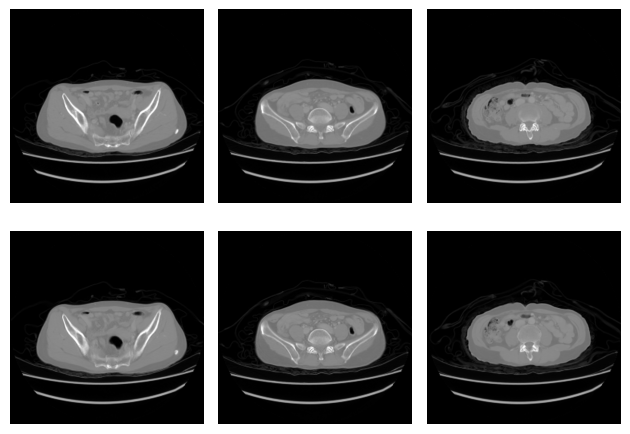

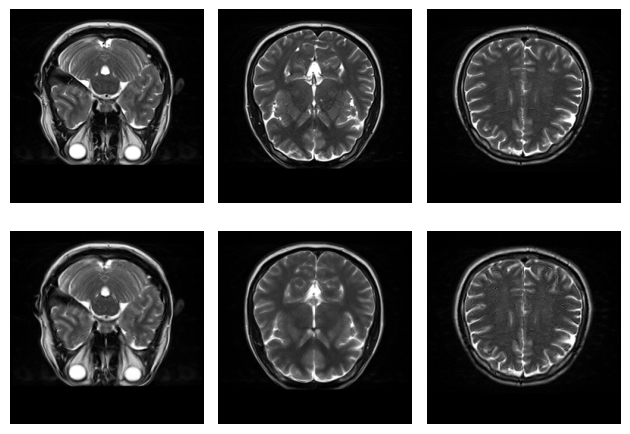

In [9]:
def tensor2volume(x: torch.Tensor):
    # x: [3, D, H, W]
    x = (x + 1.0) / 2. * 255.
    x = x[-1].clip(0, 255)

    if hasattr(x, 'cpu'):
        x = x.cpu()
    if hasattr(x, 'numpy'):
        x = x.numpy()

    return np.uint8(x)

print_array_info(recons, 'Reconstructed image tensors')
input_vols = [tensor2volume(x) for x in input_tsrs]
recon_vols = [tensor2volume(x) for x in recons]

for vol, recon_vol in zip(input_vols, recon_vols):
    num_slices = vol.shape[0]
    indices = [num_slices//3, num_slices//2, num_slices//3*2]
    orig_slices = [vol[i] for i in indices]
    recon_slices = [recon_vol[i] for i in indices]
    show_multiple_images(orig_slices + recon_slices, nrows=2)
